# Análise de Vendas do Supermercado

Este notebook apresenta a análise exploratória da base tratada de vendas,
utilizando Pandas e visualizações gráficas para responder às perguntas de
negócio propostas no projeto.

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
caminho_arquivo = "../data/processed/vendas_tratadas.csv"

df = pd.read_csv(caminho_arquivo)

df.head()

,id_venda,filial,cidade,tipo_cliente,genero,linha_produto,preco_unitario,quantidade,imposto,valor_total,data_venda,hora_venda,forma_pagamento,custo_mercadoria,margem_percentual,receita_bruta,avaliacao
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


In [23]:
# Visualizar quantidade de linhas e colunas
df.shape


(1000, 17)

## 1. Faturamento por filial

Análise do faturamento total de cada filial para identificar aquela com maior faturamento.

In [24]:
faturamento_filial = (
    df.groupby("filial")["valor_total"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)


faturamento_filial

,filial,valor_total
0,Giza,110568.7065
1,Alex,106200.3705
2,Cairo,106197.6720


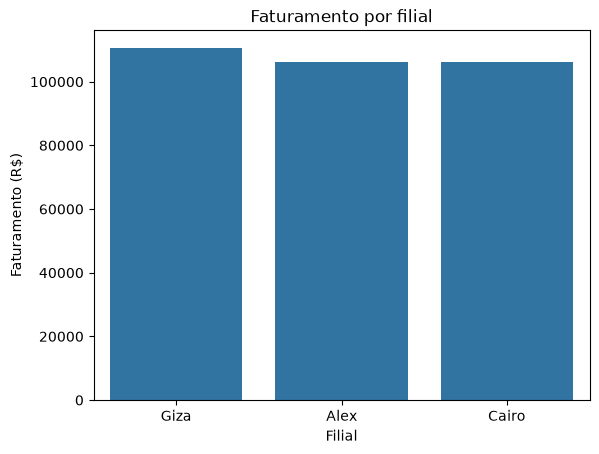

In [25]:
sns.barplot(
    data=faturamento_filial,
    x="filial",
    y="valor_total"
)

plt.title("Faturamento por filial")
plt.xlabel("Filial")
plt.ylabel("Faturamento (R$)")

plt.savefig(
    "../resultados/faturamento_filial.png",
    bbox_inches="tight"
)

**Conclusão:** A filial Giza apresentou o maior faturamento entre as três filiais analisadas, com aproximadamente 110.568,71 em vendas.

## 2. Qual filial apresentou a maior quantidade de vendas?

In [26]:
quantidade_vendas_filial = (
    df["filial"]
    .value_counts()
    .reset_index()
)

quantidade_vendas_filial

,filial,count
0,Alex,340
1,Cairo,332
2,Giza,328


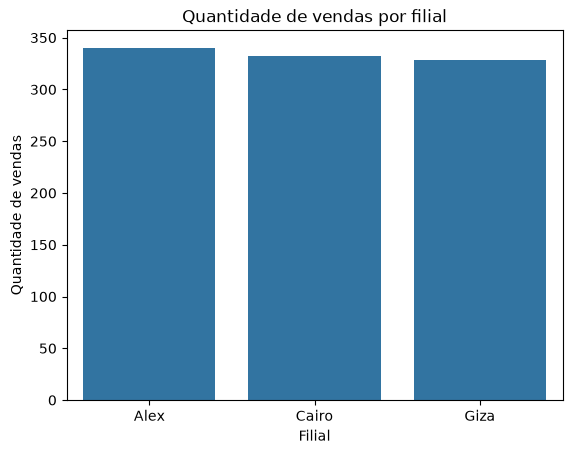

In [27]:
sns.barplot(
    data=quantidade_vendas_filial,
    x = 'filial',
    y= 'count'
)

plt.title("Quantidade de vendas por filial")
plt.xlabel("Filial")
plt.ylabel("Quantidade de vendas")

plt.savefig(
    "../resultados/quantidade_vendas_filial.png",
    bbox_inches="tight"
)

**Conclusão:** A filial Alex apresentou a maior quantidade de vendas entre as três filiais analisadas, com 340 vendas.

## 3. Qual linha de produto apresentou o maior faturamento?

In [28]:
faturamento_produto = (
    df.groupby("linha_produto")["valor_total"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)


faturamento_produto

,linha_produto,valor_total
0,Food and beverages,56144.8440
1,Sports and travel,55122.8265
2,Electronic accessories,54337.5315
3,Fashion accessories,54305.8950
4,Home and lifestyle,53861.9130
5,Health and beauty,49193.7390


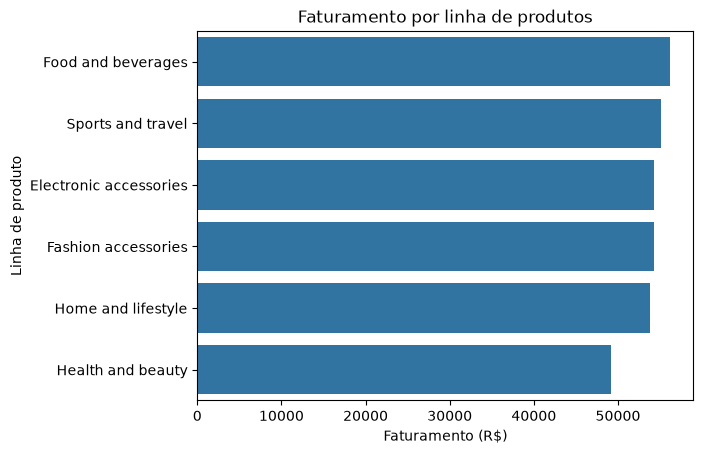

In [29]:
sns.barplot(
    data=faturamento_produto,
    x= "valor_total",
    y= "linha_produto"
)

plt.title('Faturamento por linha de produtos')
plt.xlabel('Faturamento (R$)')
plt.ylabel('Linha de produto')

plt.savefig(
    "../resultados/faturamento_produto.png",
    bbox_inches="tight"
)

**Conclusão:** A linha de produto Food and beverages apresentou o maior faturamento, com aproximadamente R$ 56.144,84 em vendas.

## 4. Qual linha de produto apresentou a melhor avaliação média?

In [30]:
avaliacao_produtos = (
    df.groupby("linha_produto")["avaliacao"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)


avaliacao_produtos

,linha_produto,avaliacao
0,Food and beverages,7.113218
1,Fashion accessories,7.029213
2,Health and beauty,7.003289
3,Electronic accessories,6.924706
4,Sports and travel,6.916265
5,Home and lifestyle,6.837500


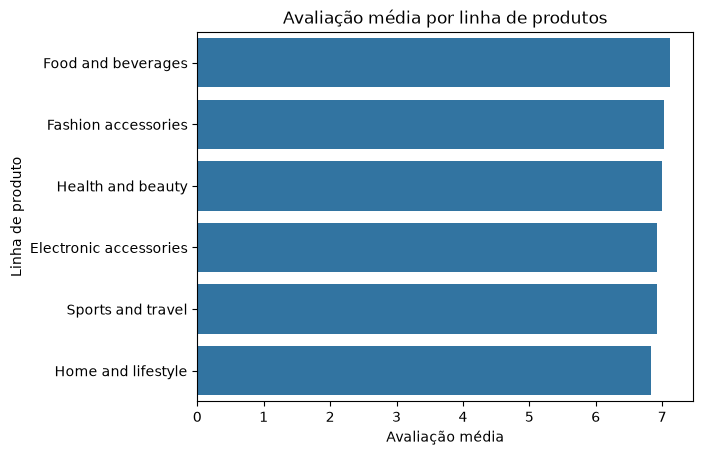

In [31]:
sns.barplot(
    data=avaliacao_produtos,
    x= "avaliacao",
    y= "linha_produto"
)

plt.title('Avaliação média por linha de produtos')
plt.xlabel('Avaliação média')
plt.ylabel('Linha de produto')

plt.savefig(
    "../resultados/avaliacao_produtos.png",
    bbox_inches="tight"
)

**Conclusão:** A linha de produto Food and beverages apresentou a maior média de avaliação por linha de produto, com a nota 7,11.

## 5. Qual foi a forma de pagamento mais utilizada?

In [32]:
vendas_pagamentos = df["forma_pagamento"].value_counts().reset_index()

vendas_pagamentos

,forma_pagamento,count
0,Ewallet,345
1,Cash,344
2,Credit card,311


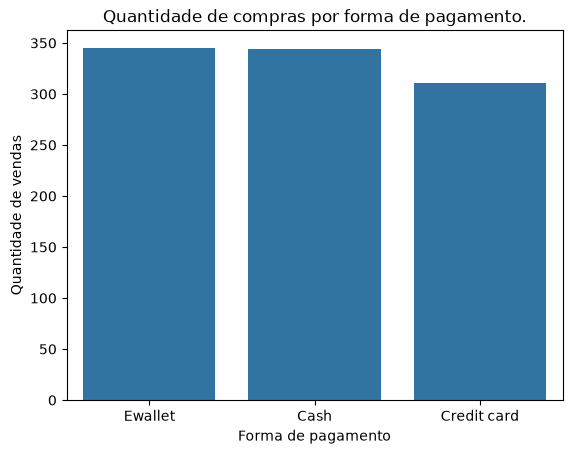

In [33]:
sns.barplot(
    data=vendas_pagamentos,
    x= "forma_pagamento",
    y= "count"
)

plt.title('Quantidade de compras por forma de pagamento.')
plt.xlabel('Forma de pagamento')
plt.ylabel('Quantidade de vendas')

plt.savefig(
    "../resultados/vendas_pagamentos.png",
    bbox_inches="tight"
)

**Conclusão:** A forma de pagamento Ewallet apresentou o maior número de compras, totalizando  345 compras.

## 6. Qual foi o valor médio das vendas?

In [34]:
media_vendas = df["valor_total"].mean()

print(f'Valor médio das vendas: R$ {media_vendas:.2f}')

Valor médio das vendas: R$ 322.97


**Conclusão:** Analisando o valor médio das vendas, chegamos ao valor de R$ 322,97.

## 7. Qual foi a maior venda registrada?

In [35]:
maior_venda = df["valor_total"].max()

venda_filtrada = df[df["valor_total"] == maior_venda]

venda_filtrada[
    [
        "id_venda",
        "filial",
        "cidade",
        "linha_produto",
        "valor_total",
        "forma_pagamento"
    ]
]

,id_venda,filial,cidade,linha_produto,valor_total,forma_pagamento
350,860-79-0874,Giza,Naypyitaw,Fashion accessories,1042.65,Credit card


**Conclusão:** A maior compra foi realizada na filial Giza, na cidade de Naypyitaw, com produtos da linha Fashion accessories. O valor da compra foi de R$ 1.042,65, utilizando Credit card como forma de pagamento.

## 8. Qual dia da semana apresentou a maior quantidade de vendas?

In [36]:
df["data_venda"] = pd.to_datetime(df["data_venda"])

df["dia_semana"] = df["data_venda"].dt.day_name()

vendas_dia_semana = (
    df["dia_semana"]
    .value_counts()
    .reset_index()
)

vendas_dia_semana

,dia_semana,count
0,Saturday,164
1,Tuesday,158
2,Wednesday,143
3,Friday,139
4,Thursday,138
5,Sunday,133
6,Monday,125


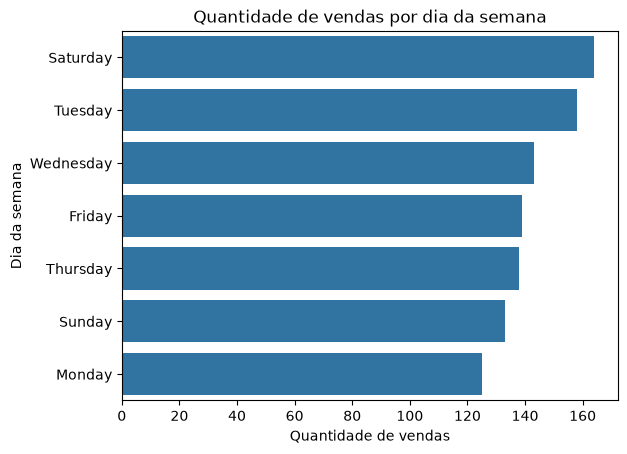

In [37]:
sns.barplot(
    data=vendas_dia_semana,
    x= "count",
    y= "dia_semana"
)

plt.title('Quantidade de vendas por dia da semana')
plt.xlabel('Quantidade de vendas')
plt.ylabel('Dia da semana')

plt.savefig(
    "../resultados/vendas_dia_semana.png",
    bbox_inches="tight"
)

**Conclusão:** Analisando o fluxo de compras por dia da semana, concluímos que sábado foi o dia com o maior número de vendas, totalizando 164 vendas.

## Estatísticas descritivas

Nesta etapa, são analisadas as principais medidas estatísticas da variável `valor_total`, permitindo observar a distribuição dos valores das vendas.

In [38]:
df['valor_total'].describe()

count    1000.000000
mean      322.966749
std       245.885335
min        10.678500
25%       124.422375
50%       253.848000
75%       471.350250
max      1042.650000
Name: valor_total, dtype: float64

**Análise:** Comparando os valores da média e da mediana, percebemos que vendas de valores mais elevados estão puxando a média para cima. Além disso, o desvio padrão de aproximadamente R$ 245,89 indica uma variação considerável entre os valores das vendas.

## Conclusão Geral

Após as análises, podemos concluir que a filial com maior faturamento foi Giza, com aproximadamente R$ 110.568,71. Entretanto, a filial com a maior quantidade de vendas foi Alex, com 340 vendas.

A linha de produtos Food and beverages se destacou tanto pelo maior faturamento quanto pela maior média de avaliação. A forma de pagamento mais utilizada foi Ewallet e, por fim, sábado foi o dia da semana com o maior número de vendas, totalizando 164 vendas.